# Error Analysis — CARLA PLN

Notebook ini menganalisis **dimana dan mengapa** model CARLA salah pada data PLN.

Urutan analisis:
1. Setup & konfigurasi
2. Jalankan inferensi ulang (per-file, per-window)
3. Score distribution (normal vs anomali)
4. ROC & PR curves
5. Confusion matrix
6. Tabel FP / FN per file
7. Time series — FP files (normal diprediksi anomali)
8. Time series — FN files (pencuri yang lolos)
9. Per-window score heatmap (file tertentu)

In [1]:
import sys, os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    confusion_matrix, f1_score
)

# ---- Resolusi path robust: cari CARLA root dari working dir ke atas ----
def _find_carla_root():
    candidates = [Path(os.path.abspath('')), Path(os.path.abspath('..'))]
    for c in candidates:
        if (c / 'carla_pretext.py').exists():
            return c
    p = Path(os.path.abspath(''))
    for _ in range(5):
        if (p / 'carla_pretext.py').exists():
            return p
        p = p.parent
    raise RuntimeError('CARLA root tidak ditemukan. Jalankan Jupyter dari D:/CARLA atau D:/CARLA/notebooks.')

BASE_DIR = _find_carla_root()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
os.chdir(BASE_DIR)  # pastikan path relatif dari create_config resolve benar

from utils.config import create_config
from utils.common_config import get_model, get_val_transformations1, inject_sub_anomaly
from utils.collate import collate_custom
from utils.dataset_channels import get_pln_train_files, get_pln_test_files
from data.PLN import PLN

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {device}')
print(f'BASE_DIR: {BASE_DIR}')

Device  : cpu
BASE_DIR: c:\CARLA-20260708-1450


## 1. Konfigurasi

Ganti `AGG` dan `SEED` sesuai model yang ingin dianalisis.

In [2]:
# ============================================================
# KONFIGURASI — sesuaikan di sini
# ============================================================
AGG   = 'mean'   # 'mean' | 'max' | 'pct95'
SEED  = None     # None = default (no suffix) | 0, 1, 2, ... untuk multiseed

CONFIG_ENV = str(BASE_DIR / 'configs' / 'env.yml')
CONFIG_CLS = str(BASE_DIR / 'configs' / 'classification' / 'carla_classification_pln.yml')

# Handle backward compat: create_config versi lama mungkin tidak punya param seed
import inspect
_cc_params = inspect.signature(create_config).parameters
if 'seed' in _cc_params:
    p = create_config(CONFIG_ENV, CONFIG_CLS, 'All', seed=SEED)
else:
    p = create_config(CONFIG_ENV, CONFIG_CLS, 'All')


# Build TAG: anomaly_type + AGG + seed
# Suffix unik untuk setiap kombinasi — tidak akan menimpa run lain
# Contoh: 'subseq_mean', 'theft_max', 'theft+subseq_mean_s0'
_atype = (p.get('anomaly_kwargs') or {}).get('type', 'subseq') or 'subseq'
_seed_tag = '' if SEED is None else f'_s{SEED}'
TAG = f'{_atype}_{AGG}{_seed_tag}'
MODEL_PATH = p['classification_model']
print(f'Model path : {MODEL_PATH}')
print(f'Aggregation: {AGG}')
print(f'Anomaly    : {_atype}')
print(f'TAG        : {TAG}  <- suffix semua file output')
assert Path(MODEL_PATH).exists(), f'Model belum ada: {MODEL_PATH}. Jalankan run_pln.py dahulu.'

Model path : results/pln\All/classification\model.pth.tar
Aggregation: mean


## 2. Load Model & Inferensi Per-File + Per-Window

In [3]:
# --- Load model ---
model = get_model(p)
model = torch.nn.DataParallel(model)
ckpt  = torch.load(MODEL_PATH, map_location='cpu', weights_only=False)
model.module.load_state_dict(ckpt['model'])
model.to(device).eval()

val_transform = get_val_transformations1(p)
sanomaly      = inject_sub_anomaly(p)

@torch.no_grad()
def get_logits(model, ts):
    if ts.ndim == 3:
        b, w, h = ts.shape
    else:
        b, w = ts.shape; h = 1
    out = model(ts.view(b, h, w))
    return out[0] if isinstance(out, (list, tuple)) else out

# --- Cari normal_label dari training pool (majority vote) ---
train_files = get_pln_train_files()
train_ds = None
for fname in train_files:
    ds = PLN(fname, train=True, transform=val_transform, sanomaly=sanomaly)
    if train_ds is None:
        train_ds = ds
    else:
        train_ds.concat_ds(ds)

train_dl = torch.utils.data.DataLoader(
    train_ds, batch_size=p['batch_size'], shuffle=False,
    num_workers=p['num_workers'], collate_fn=collate_custom, drop_last=False)

all_preds = []
with torch.no_grad():
    for batch in train_dl:
        ts = batch['ts_org'].to(device)
        preds = torch.argmax(get_logits(model, ts), dim=1).cpu().numpy()
        all_preds.append(preds)
all_preds = np.concatenate(all_preds)
values, counts = np.unique(all_preds, return_counts=True)
normal_label = int(values[np.argmax(counts)])
print(f'Normal label (majority): {normal_label}  ({dict(zip(values.tolist(), counts.tolist()))})')

Normal label (majority): 0  ({0: 24849, 1: 303, 3: 2114, 4: 11, 5: 2116, 6: 3505, 8: 10571, 9: 363})


In [4]:
def aggregate_scores(scores, method='mean'):
    if method == 'mean':  return float(np.mean(scores))
    if method == 'max':   return float(np.max(scores))
    if method == 'pct95': return float(np.percentile(scores, 95))
    return float(np.mean(scores))

# --- Inferensi per file ---
test_files  = get_pln_test_files()
rows        = []   # per-file
window_data = {}   # per-window, per file

with torch.no_grad():
    for fname in test_files:
        ds = PLN(fname, train=False, transform=val_transform, sanomaly=sanomaly)
        dl = torch.utils.data.DataLoader(
            ds, batch_size=p['batch_size'], shuffle=False,
            num_workers=p['num_workers'], collate_fn=collate_custom, drop_last=False)

        win_scores, win_labels = [], []
        raw_windows = []
        for batch in dl:
            ts     = batch['ts_org'].to(device)
            logits = get_logits(model, ts)
            probs  = F.softmax(logits, dim=1).cpu().numpy()
            scores = 1.0 - probs[:, normal_label]
            win_scores.extend(scores.tolist())
            win_labels.extend(batch['target'].cpu().numpy().tolist())
            raw_windows.append(batch['ts_org'].cpu().numpy())

        win_scores = np.array(win_scores)
        true_label = int(win_labels[0])
        file_score = aggregate_scores(win_scores, AGG)

        rows.append({
            'fname':      fname,
            'true_label': true_label,
            'score':      file_score,
            'n_windows':  len(win_scores),
            'score_min':  float(win_scores.min()),
            'score_max':  float(win_scores.max()),
            'score_std':  float(win_scores.std()),
        })
        window_data[fname] = {
            'win_scores':  win_scores,
            'raw_windows': np.concatenate(raw_windows, axis=0),
            'true_label':  true_label,
        }

df = pd.DataFrame(rows)
print(f'Total file test: {len(df)}  (normal: {(df.true_label==0).sum()}, anomali: {(df.true_label==1).sum()})')
df.head(10)

Total file test: 25  (normal: 15, anomali: 10)


,fname,true_label,score,n_windows,score_min,score_max,score_std
0,120030005909-a.npy,1,0.544597,444,0.060765,0.999667,0.326673
1,120030745857-a.npy,1,0.612110,573,0.051252,0.999879,0.257216
2,120120158879-a.npy,1,0.828713,108,0.239645,0.998184,0.173208
3,121101064783-a.npy,1,0.799328,630,0.101344,1.000000,0.215564
4,121160469026-a.npy,1,0.555002,503,0.050280,0.999530,0.289948
5,121170436934-a.npy,1,0.780803,477,0.117325,1.000000,0.201773
6,121170485044-a.npy,1,0.600225,646,0.079779,0.992534,0.263277
7,122130645743-a.npy,1,0.349191,30,0.105798,0.881940,0.236819
8,125100007230-a.npy,1,0.999569,138,0.994235,0.999943,0.000974
9,126150138887-a.npy,1,0.626221,1003,0.055889,0.998554,0.236766


In [5]:
# --- Hitung threshold & label prediksi ---
file_scores = df['score'].values
file_labels = df['true_label'].values

prec_curve, rec_curve, thr_pr = precision_recall_curve(file_labels, file_scores)
f1_curve = np.where(
    (prec_curve + rec_curve) > 0,
    2 * prec_curve * rec_curve / (prec_curve + rec_curve), 0.0)
best_idx  = int(np.argmax(f1_curve[:-1]))
THRESHOLD = float(thr_pr[best_idx])

df['pred_label'] = (df['score'] >= THRESHOLD).astype(int)
df['result'] = df.apply(lambda r:
    'TP' if r.true_label==1 and r.pred_label==1 else
    'TN' if r.true_label==0 and r.pred_label==0 else
    'FP' if r.true_label==0 and r.pred_label==1 else 'FN', axis=1)

auroc = roc_auc_score(file_labels, file_scores) if len(np.unique(file_labels)) > 1 else float('nan')
aupr  = average_precision_score(file_labels, file_scores)
f1    = f1_score(file_labels, df['pred_label'].values, zero_division=0)

print(f'Threshold : {THRESHOLD:.4f}')
print(f'AUROC     : {auroc:.4f}')
print(f'AUPR      : {aupr:.4f}')
print(f'F1 anomaly: {f1:.4f}')
print(f"\nDistribusi: {df['result'].value_counts().to_dict()}")

Threshold : 0.5446
AUROC     : 0.8200
AUPR      : 0.8058
F1 anomaly: 0.8182

Distribusi: {'TN': 12, 'TP': 9, 'FP': 3, 'FN': 1}


## 3. Score Distribution

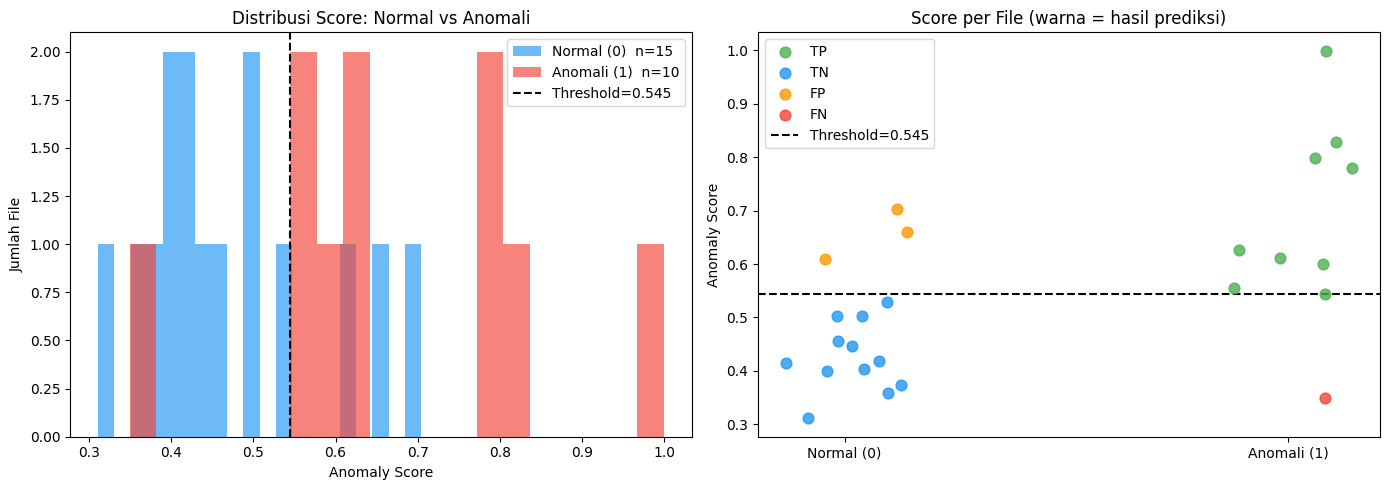

Saved: c:\CARLA-20260708-1450\results\figures\error_pln_score_dist_mean.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
ax = axes[0]
for lbl, col, name in [(0, '#2196F3', 'Normal (0)'), (1, '#F44336', 'Anomali (1)')]:
    scores_sub = df[df.true_label == lbl]['score'].values
    ax.hist(scores_sub, bins=20, alpha=0.65, color=col, label=f'{name}  n={len(scores_sub)}')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.5, label=f'Threshold={THRESHOLD:.3f}')
ax.set_xlabel('Anomaly Score')
ax.set_ylabel('Jumlah File')
ax.set_title('Distribusi Score: Normal vs Anomali')
ax.legend()

# Strip plot per file, warna TP/TN/FP/FN
ax2 = axes[1]
result_colors = {'TP': '#4CAF50', 'TN': '#2196F3', 'FP': '#FF9800', 'FN': '#F44336'}
rng = np.random.default_rng(42)
for res, col in result_colors.items():
    sub = df[df.result == res]
    if len(sub) == 0: continue
    x_base = 0 if sub.true_label.iloc[0] == 0 else 1
    x = rng.uniform(-0.15, 0.15, len(sub)) + x_base
    ax2.scatter(x, sub['score'].values, color=col, alpha=0.8, s=60, label=res, zorder=3)
ax2.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.5, label=f'Threshold={THRESHOLD:.3f}')
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Normal (0)', 'Anomali (1)'])
ax2.set_ylabel('Anomaly Score')
ax2.set_title('Score per File (warna = hasil prediksi)')
ax2.legend()

plt.tight_layout()
out_path = BASE_DIR / 'results' / 'figures' / f'error_pln_score_dist_{TAG}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

## 4. ROC & PR Curves

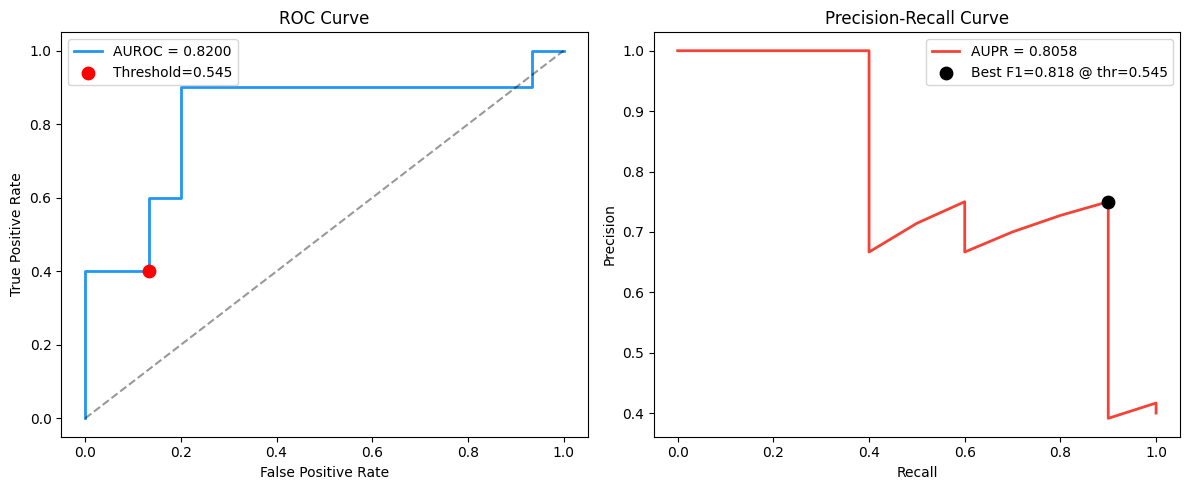

Saved: c:\CARLA-20260708-1450\results\figures\error_pln_roc_pr_mean.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
if not np.isnan(auroc):
    fpr, tpr, thr_roc = roc_curve(file_labels, file_scores)
    ax.plot(fpr, tpr, color='#2196F3', lw=2, label=f'AUROC = {auroc:.4f}')
    thr_idx = np.searchsorted(np.sort(thr_roc), THRESHOLD)
    thr_idx = min(thr_idx, len(fpr) - 1)
    ax.scatter([fpr[thr_idx]], [tpr[thr_idx]], color='red', zorder=5, s=80,
               label=f'Threshold={THRESHOLD:.3f}')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()

# PR
ax2 = axes[1]
ax2.plot(rec_curve, prec_curve, color='#F44336', lw=2, label=f'AUPR = {aupr:.4f}')
ax2.scatter([rec_curve[best_idx]], [prec_curve[best_idx]], color='black', zorder=5, s=80,
            label=f'Best F1={f1:.3f} @ thr={THRESHOLD:.3f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend()

plt.tight_layout()
out_path = BASE_DIR / 'results' / 'figures' / f'error_pln_roc_pr_{TAG}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

## 5. Confusion Matrix

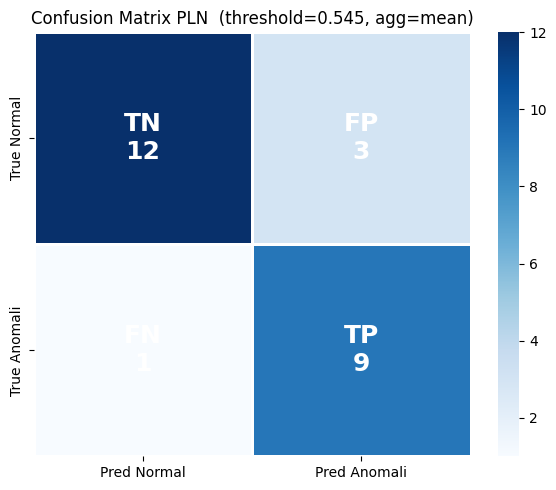

TN=12  FP=3  FN=1  TP=9
Saved: c:\CARLA-20260708-1450\results\figures\error_pln_confusion_mean.png


In [8]:
cm = confusion_matrix(file_labels, df['pred_label'].values, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
            xticklabels=['Pred Normal', 'Pred Anomali'],
            yticklabels=['True Normal', 'True Anomali'],
            linewidths=1, linecolor='white')

cell_labels = [[f'TN\n{tn}', f'FP\n{fp}'], [f'FN\n{fn}', f'TP\n{tp}']]
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, cell_labels[i][j],
                ha='center', va='center', fontsize=18, fontweight='bold', color='white')

ax.set_title(f'Confusion Matrix PLN — {TAG}\n(threshold={THRESHOLD:.3f})', fontsize=11)
plt.tight_layout()
out_path = BASE_DIR / 'results' / 'figures' / f'error_pln_confusion_{TAG}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'Saved: {out_path}')

## 6. Tabel FP / FN Per File

In [9]:
cols_show = ['fname', 'true_label', 'pred_label', 'score', 'score_min', 'score_max', 'score_std', 'n_windows', 'result']

print('=== FALSE POSITIVE (normal diprediksi anomali) ===')
fp_df = df[df.result == 'FP'][cols_show].sort_values('score', ascending=False)
display(fp_df)

print('\n=== FALSE NEGATIVE (anomali lolos / tidak terdeteksi) ===')
fn_df = df[df.result == 'FN'][cols_show].sort_values('score', ascending=True)
display(fn_df)

print('\n=== SEMUA FILE (diurutkan berdasarkan score) ===')
def highlight_result(row):
    color_map = {'TP': 'background-color: #c8e6c9',
                 'TN': 'background-color: #bbdefb',
                 'FP': 'background-color: #ffe0b2',
                 'FN': 'background-color: #ffcdd2'}
    return [color_map.get(row.result, '')] * len(row)

display(df[cols_show].sort_values('score', ascending=False)
        .style.apply(highlight_result, axis=1)
        .format({'score': '{:.4f}', 'score_min': '{:.4f}',
                 'score_max': '{:.4f}', 'score_std': '{:.4f}'}))

=== FALSE POSITIVE (normal diprediksi anomali) ===


,fname,true_label,pred_label,score,score_min,score_max,score_std,n_windows,result
23,126150440585-n.npy,0,1,0.703903,0.062771,1.000000,0.226651,1403,FP
12,120011052623-n.npy,0,1,0.659563,0.071074,0.995443,0.272788,940,FP
11,120011001721-n.npy,0,1,0.608618,0.124605,0.996256,0.275729,127,FP



=== FALSE NEGATIVE (anomali lolos / tidak terdeteksi) ===


,fname,true_label,pred_label,score,score_min,score_max,score_std,n_windows,result
7,122130645743-a.npy,1,0,0.349191,0.105798,0.88194,0.236819,30,FN



=== SEMUA FILE (diurutkan berdasarkan score) ===


,fname,true_label,pred_label,score,score_min,score_max,score_std,n_windows,result
8,125100007230-a.npy,1,1,0.9996,0.9942,0.9999,0.0010,138,TP
2,120120158879-a.npy,1,1,0.8287,0.2396,0.9982,0.1732,108,TP
3,121101064783-a.npy,1,1,0.7993,0.1013,1.0000,0.2156,630,TP
5,121170436934-a.npy,1,1,0.7808,0.1173,1.0000,0.2018,477,TP
23,126150440585-n.npy,0,1,0.7039,0.0628,1.0000,0.2267,1403,FP
12,120011052623-n.npy,0,1,0.6596,0.0711,0.9954,0.2728,940,FP
9,126150138887-a.npy,1,1,0.6262,0.0559,0.9986,0.2368,1003,TP
1,120030745857-a.npy,1,1,0.6121,0.0513,0.9999,0.2572,573,TP
11,120011001721-n.npy,0,1,0.6086,0.1246,0.9963,0.2757,127,FP
6,121170485044-a.npy,1,1,0.6002,0.0798,0.9925,0.2633,646,TP


## 7. Time Series — False Positive Files

File **normal** yang diprediksi anomali. Cari pola apa yang membuat model bingung.

FP files (3): ['120011001721-n.npy', '120011052623-n.npy', '126150440585-n.npy']


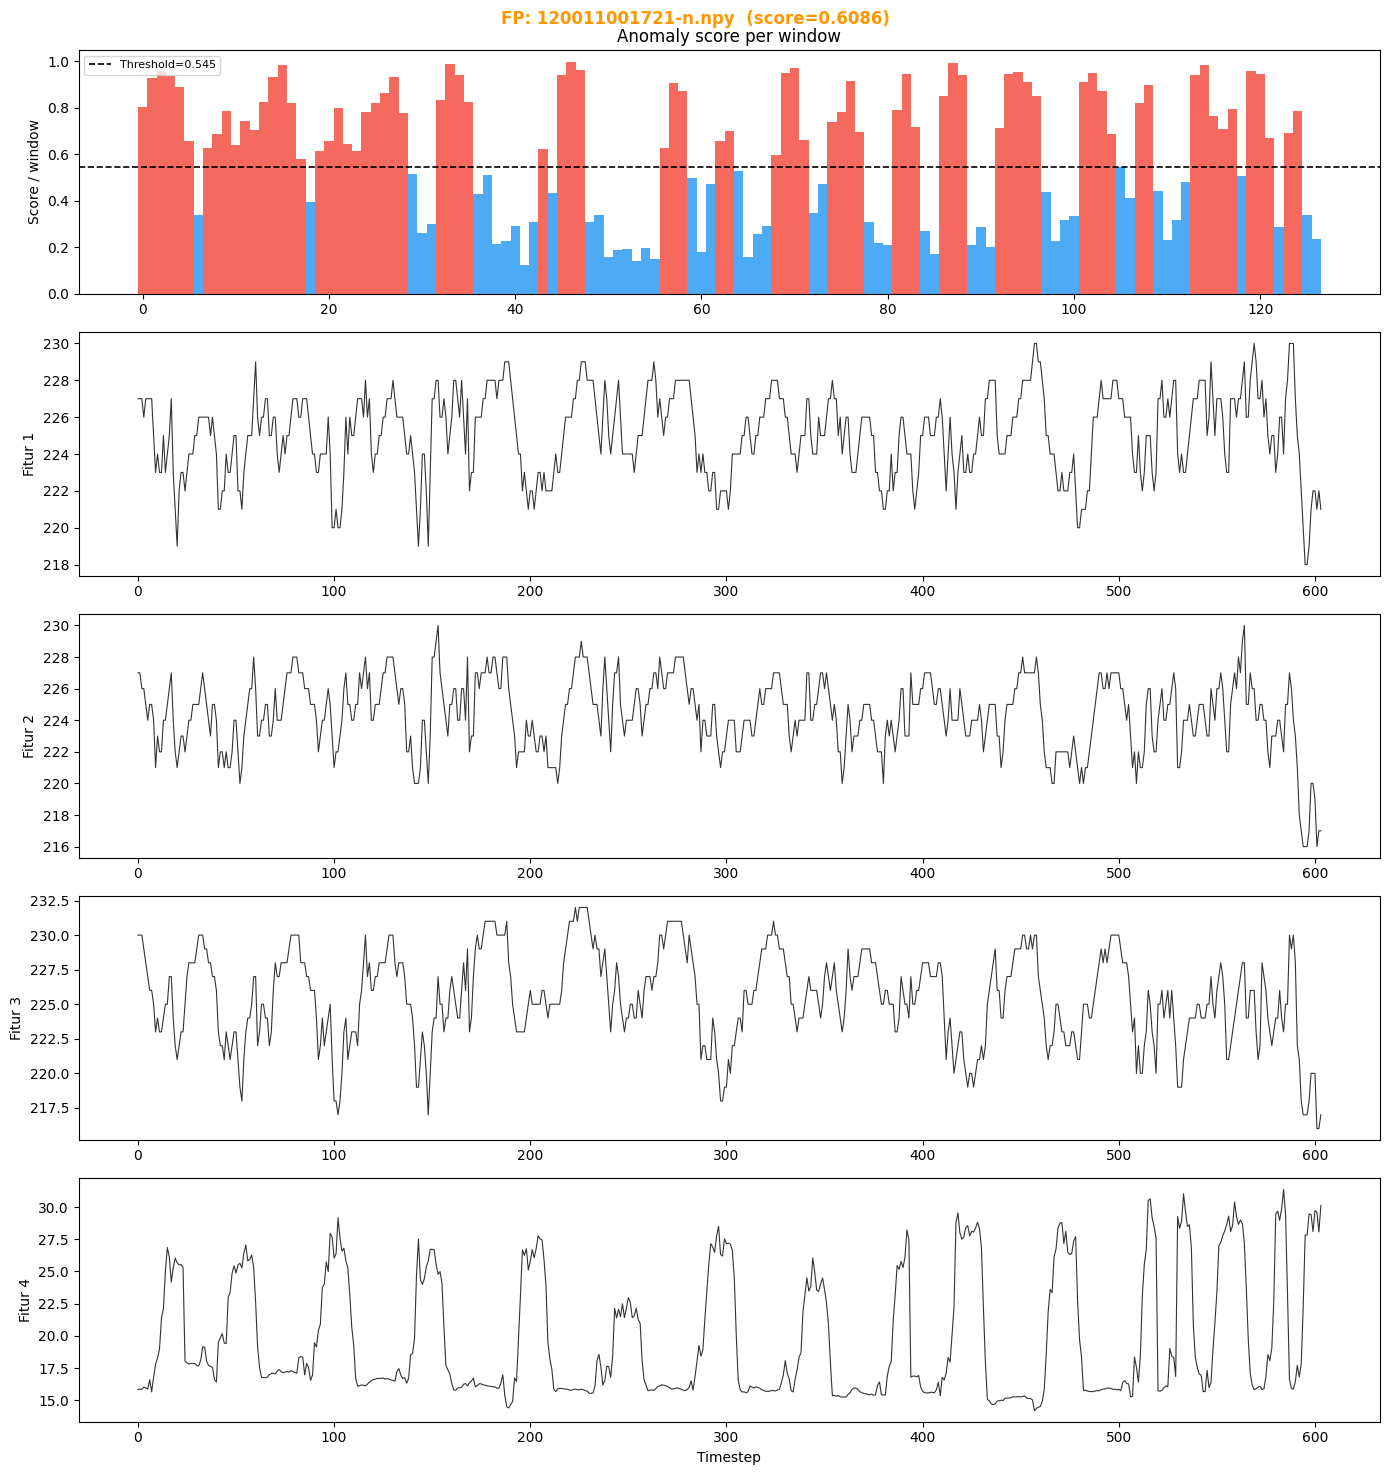

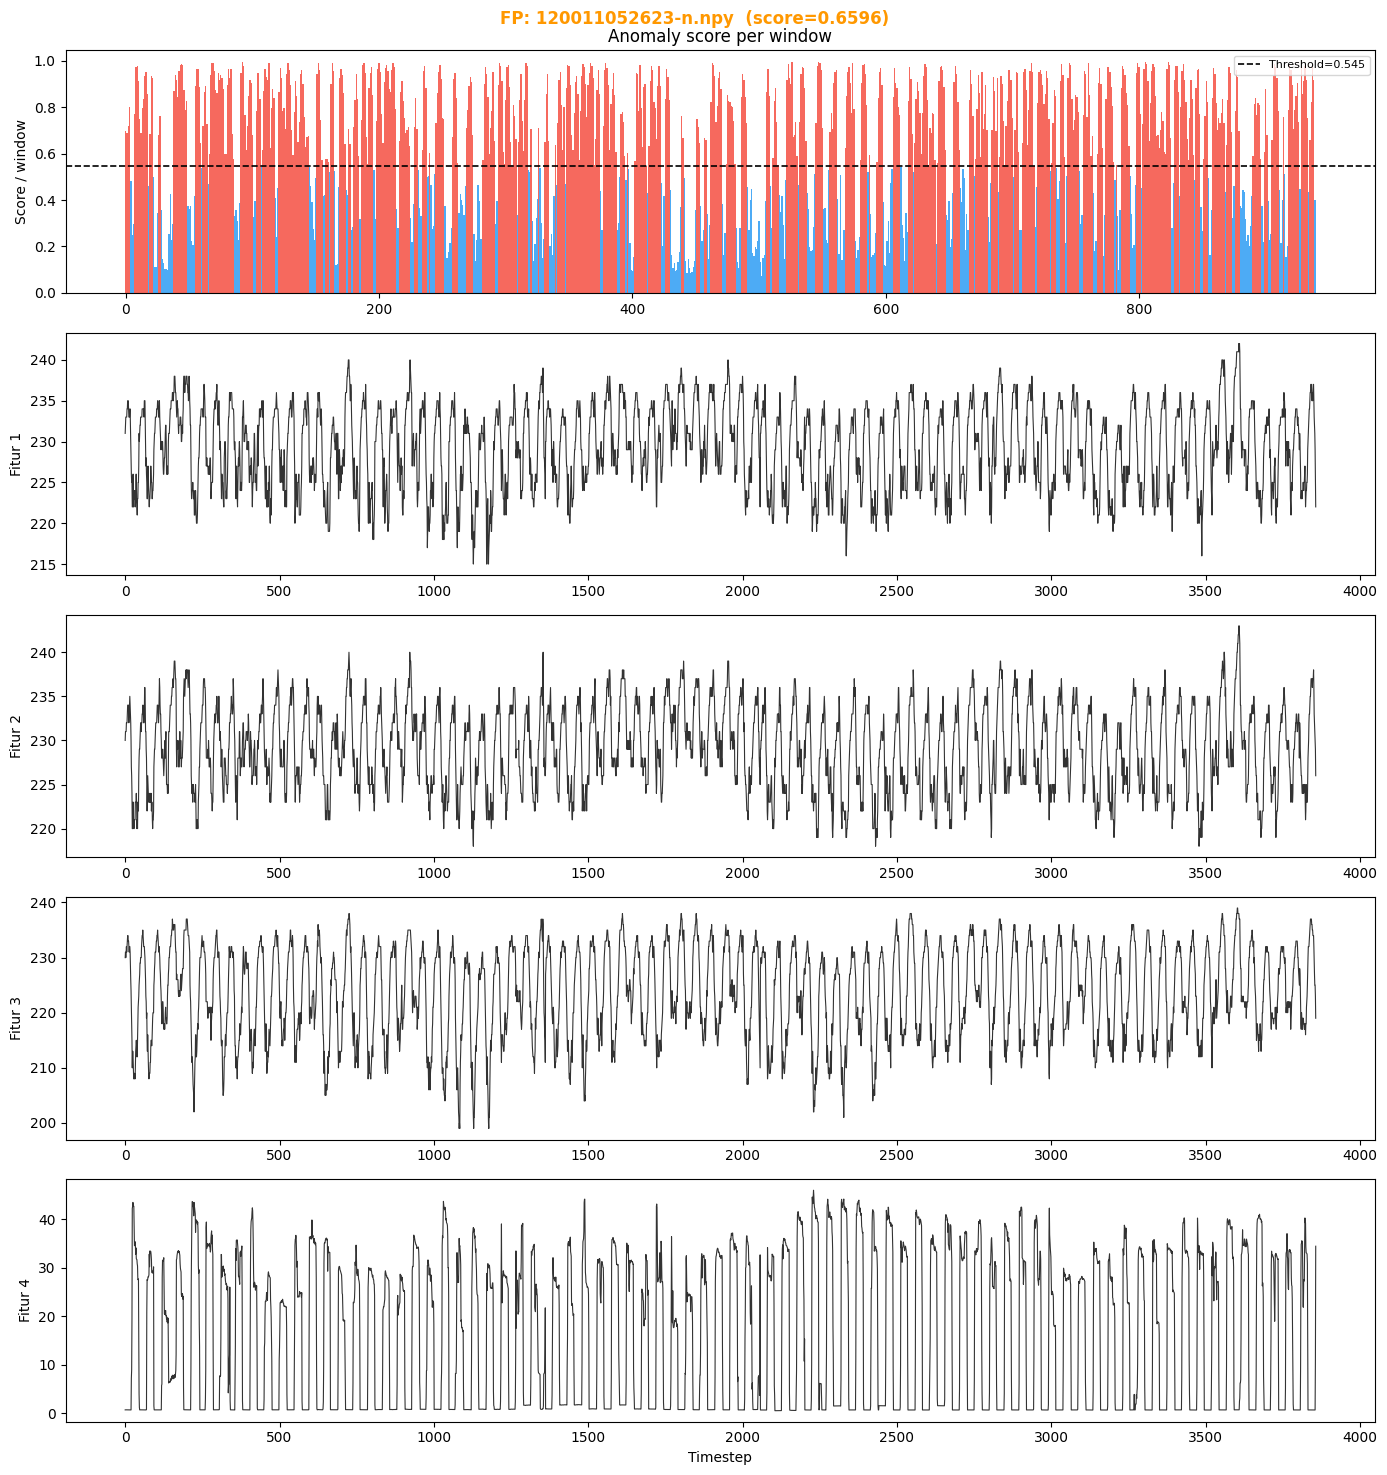

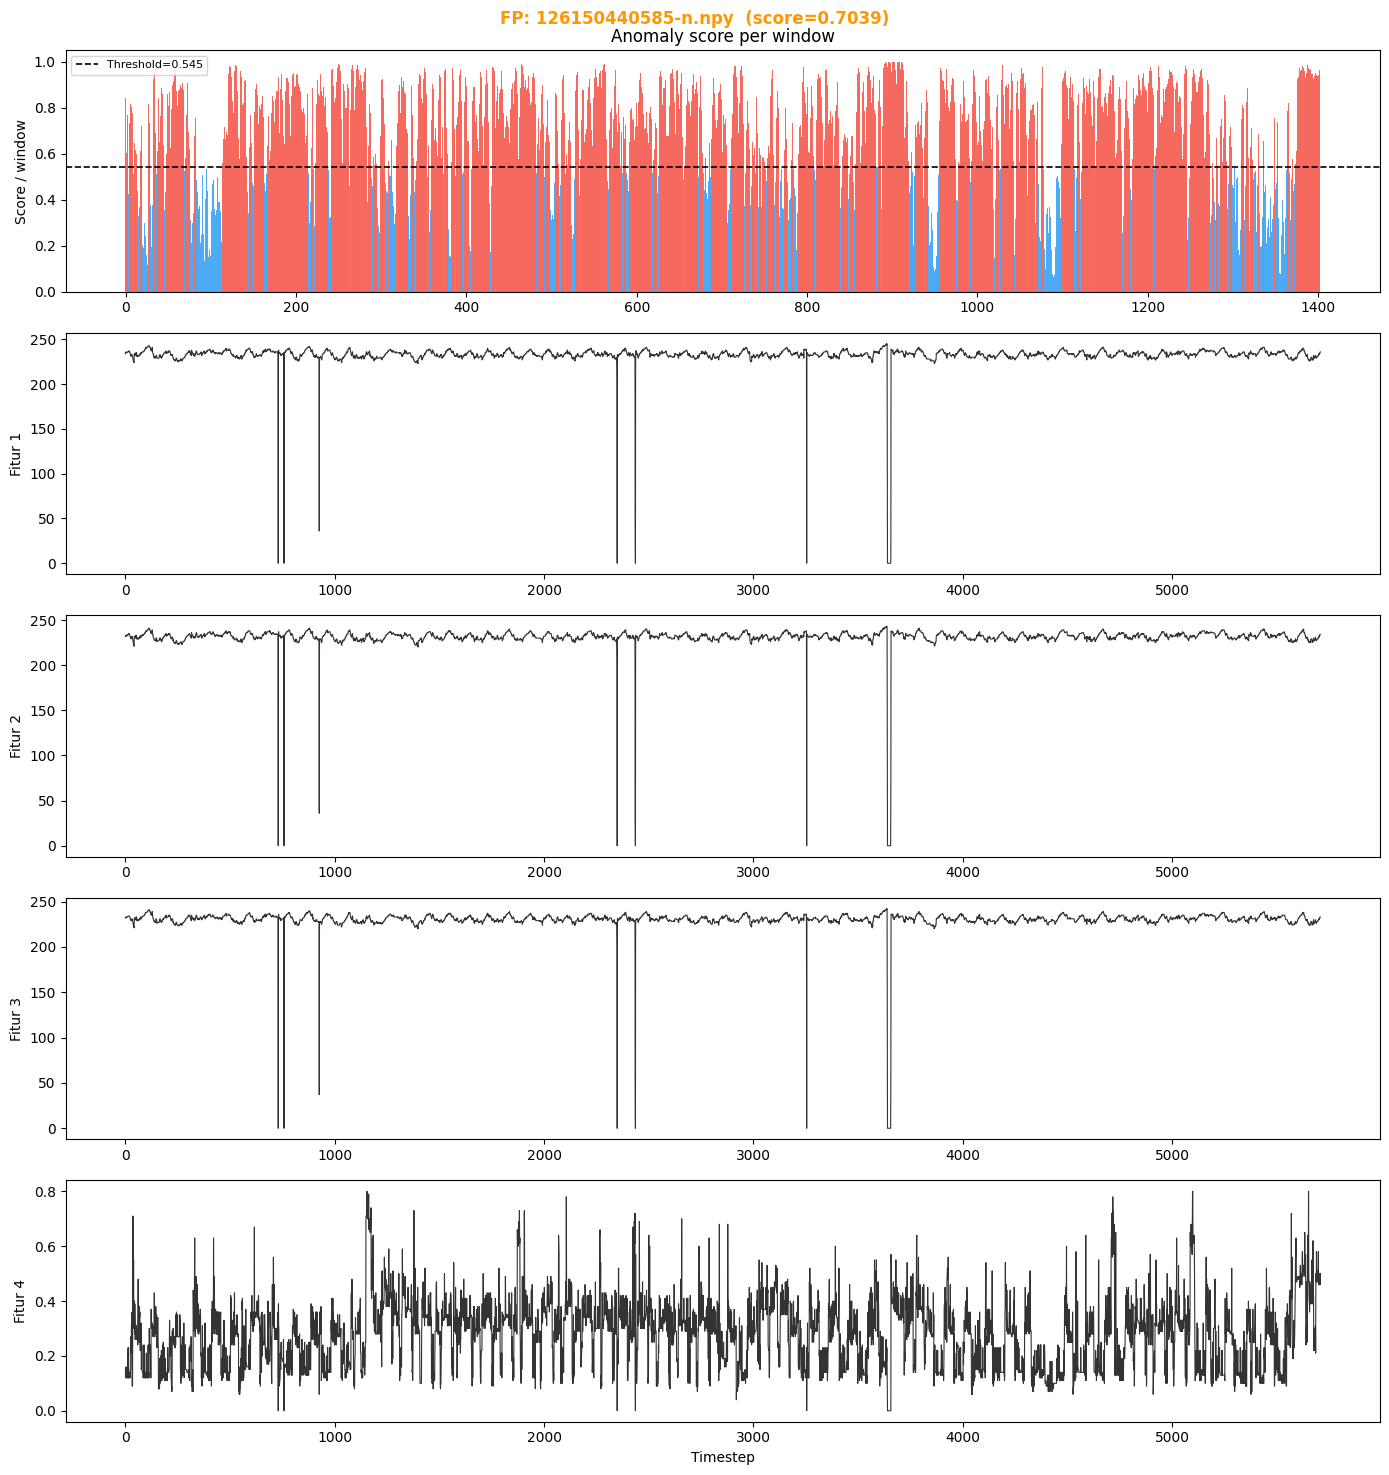

In [10]:
def plot_file_timeseries(fname, result_label, max_features=4):
    """Plot time series lengkap file + bar skor anomali per window."""
    data = window_data[fname]
    win_scores = data['win_scores']

    # Load time series asli dari .npy
    npy_path = BASE_DIR / 'datasets' / 'PLN' / 'processed' / 'data' / fname
    if not str(npy_path).endswith('.npy'):
        npy_path = Path(str(npy_path) + '.npy')
    full_ts = np.load(str(npy_path)) if npy_path.exists() else data['raw_windows'][0]

    n_features = min(full_ts.shape[1] if full_ts.ndim > 1 else 1, max_features)
    title_color = {'FP': '#FF9800', 'FN': '#F44336', 'TP': '#4CAF50', 'TN': '#2196F3'}.get(result_label, 'black')
    file_score  = df.loc[df.fname == fname, 'score'].values[0]

    fig, axes = plt.subplots(n_features + 1, 1, figsize=(14, 3 * (n_features + 1)), sharex=False)
    fig.suptitle(f'[{TAG}]  {result_label}: {fname}  (score={file_score:.4f})',
                 fontsize=11, fontweight='bold', color=title_color)

    # Panel atas: skor per window
    ax0 = axes[0] if n_features > 0 else axes
    bar_colors = ['#F44336' if s >= THRESHOLD else '#2196F3' for s in win_scores]
    ax0.bar(range(len(win_scores)), win_scores, color=bar_colors, width=1.0, alpha=0.8)
    ax0.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.2,
                label=f'Threshold={THRESHOLD:.3f}')
    ax0.set_ylabel('Score / window')
    ax0.set_title('Anomaly score per window')
    ax0.legend(fontsize=8)

    # Panel bawah: fitur time series
    for i in range(n_features):
        ax = axes[i + 1]
        col = full_ts[:, i] if full_ts.ndim > 1 else full_ts
        ax.plot(col, color='#333333', linewidth=0.8)
        ax.set_ylabel(f'Fitur {i+1}')
        if i == n_features - 1:
            ax.set_xlabel('Timestep')

    plt.tight_layout()
    safe_name = fname.replace('.npy', '')[:20]
    out_path = BASE_DIR / 'results' / 'figures' / f'error_pln_{result_label}_{TAG}_{safe_name}.png'
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    plt.close()


fp_files = df[df.result == 'FP']['fname'].tolist()
if fp_files:
    print(f'FP files ({len(fp_files)}): {fp_files}')
    for fname in fp_files[:5]:
        plot_file_timeseries(fname, 'FP')
else:
    print('Tidak ada False Positive.')

## 8. Time Series — False Negative Files

File **anomali** yang lolos (diprediksi normal). Ini paling kritis untuk deteksi pencurian listrik.

FN files (1): ['122130645743-a.npy']


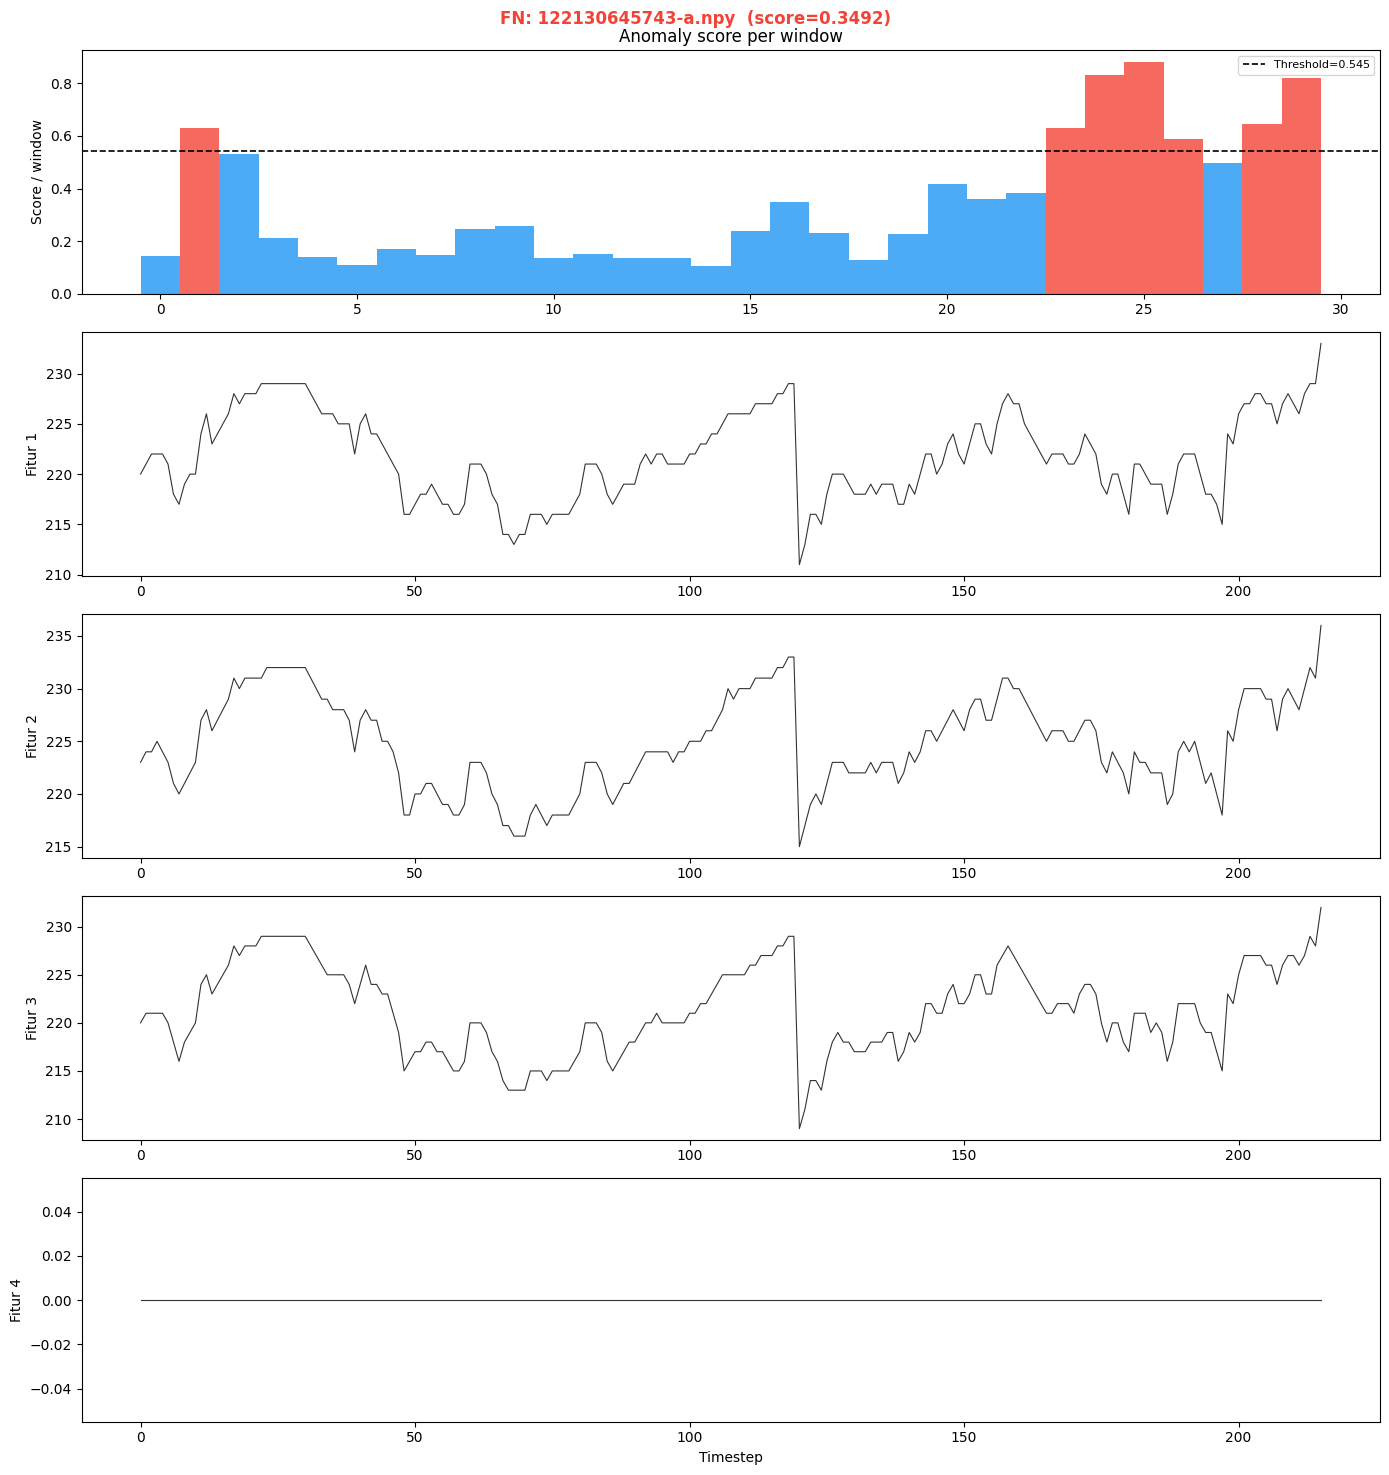

In [11]:
fn_files = df[df.result == 'FN']['fname'].tolist()
if fn_files:
    print(f'FN files ({len(fn_files)}): {fn_files}')
    for fname in fn_files[:5]:
        plot_file_timeseries(fname, 'FN')
else:
    print('Tidak ada False Negative — semua pencuri terdeteksi!')

## 9. Per-Window Score Heatmap

Pilih satu file untuk diinspeksi lebih dalam — bagian mana dari time series yang mencurigakan.

File   : 122130645743-a.npy
Label  : 1  |  Pred: 0  |  Result: FN
Score  : 0.3492  (min=0.1058, max=0.8819)


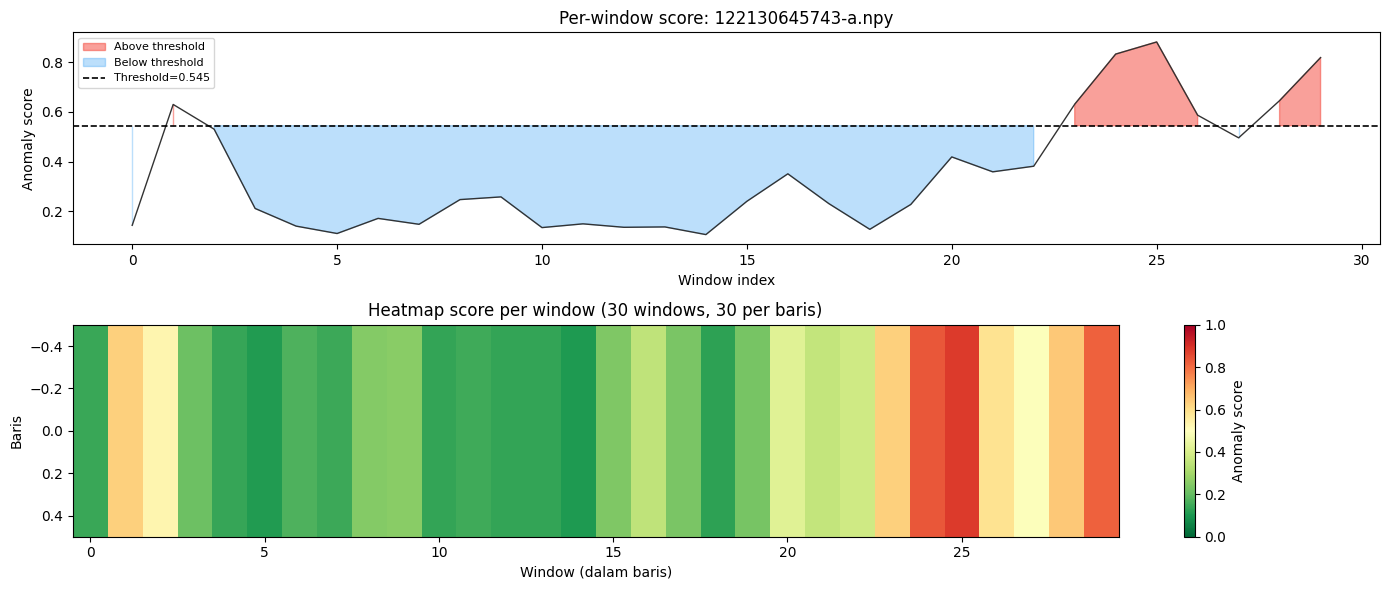

Saved: c:\CARLA-20260708-1450\results\figures\error_pln_heatmap_122130645743-a.png


In [12]:
# Ganti fname_target jika ingin inspeksi file lain
candidates  = fn_files + fp_files
fname_target = candidates[0] if candidates else df['fname'].iloc[0]

row_target = df[df.fname == fname_target].iloc[0]
print(f'File   : {fname_target}')
print(f'Label  : {row_target.true_label}  |  Pred: {row_target.pred_label}  |  Result: {row_target.result}')
print(f'Score  : {row_target.score:.4f}  (min={row_target.score_min:.4f}, max={row_target.score_max:.4f})')

wscores = window_data[fname_target]['win_scores']
N_win   = len(wscores)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Line + fill
ax = axes[0]
ax.plot(wscores, color='#333333', linewidth=1)
ax.fill_between(range(N_win), wscores, THRESHOLD,
                where=(wscores >= THRESHOLD), color='#F44336', alpha=0.5, label='Above threshold')
ax.fill_between(range(N_win), wscores, THRESHOLD,
                where=(wscores < THRESHOLD),  color='#2196F3', alpha=0.3, label='Below threshold')
ax.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.2, label=f'Threshold={THRESHOLD:.3f}')
ax.set_xlabel('Window index')
ax.set_ylabel('Anomaly score')
fig.suptitle(f'[{TAG}]  Per-window score: {fname_target}', fontsize=11, fontweight='bold')
ax.set_title('Score per window')
ax.legend(fontsize=8)

# Heatmap
ax2 = axes[1]
n_cols = min(N_win, 50)
n_rows = int(np.ceil(N_win / n_cols))
padded = np.pad(wscores, (0, n_rows * n_cols - N_win), constant_values=np.nan)
heatmap_data = padded.reshape(n_rows, n_cols)

im = ax2.imshow(heatmap_data, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=1)
plt.colorbar(im, ax=ax2, label='Anomaly score')
ax2.set_xlabel('Window (dalam baris)')
ax2.set_ylabel('Baris')
ax2.set_title(f'Heatmap score per window ({N_win} windows, {n_cols} per baris)')

plt.tight_layout()
safe_name = fname_target.replace('.npy', '')[:20]
out_path = BASE_DIR / 'results' / 'figures' / f'error_pln_heatmap_{TAG}_{safe_name}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

## 10. Ringkasan Error Analysis

In [13]:
print('=' * 55)
print(f'  ERROR ANALYSIS — PLN  [{TAG}]')
print('=' * 55)
print(f'  Total file test : {len(df)}')
print(f'  Normal          : {(df.true_label==0).sum()}')
print(f'  Anomali         : {(df.true_label==1).sum()}')
print(f'  Threshold       : {THRESHOLD:.4f}  (auto: max F1 pada PR curve)')
print(f'  AUROC           : {auroc:.4f}')
print(f'  AUPR            : {aupr:.4f}')
print(f'  F1 anomaly      : {f1:.4f}')
print(f'  TP={tp}  TN={tn}  FP={fp}  FN={fn}')
print('-' * 55)

if fp > 0:
    print(f'  FP ({fp} file) — normal diprediksi anomali:')
    for _, row in fp_df.iterrows():
        print(f'    {row.fname}  score={row.score:.4f}  std={row.score_std:.4f}')

if fn > 0:
    print(f'  FN ({fn} file) — pencuri yang lolos:')
    for _, row in fn_df.iterrows():
        print(f'    {row.fname}  score={row.score:.4f}  std={row.score_std:.4f}')

print('=' * 55)
print('Interpretasi FN : pencuri dengan pola mirip normal (score rendah & konsisten).')
print('Interpretasi FP : pelanggan normal dengan variasi pola tidak biasa.')
print(f'\nSemua figure tersimpan di: results/figures/error_pln_*_{TAG}*.png')

  ERROR ANALYSIS — PLN  (agg=mean)
  Total file test : 25
  Normal          : 15
  Anomali         : 10
  Threshold       : 0.5446  (auto: max F1 pada PR curve)
  AUROC           : 0.8200
  AUPR            : 0.8058
  F1 anomaly      : 0.8182
  TP=9  TN=12  FP=3  FN=1
-------------------------------------------------------
  FP (3 file) — normal diprediksi anomali:
    126150440585-n.npy  score=0.7039  std=0.2267
    120011052623-n.npy  score=0.6596  std=0.2728
    120011001721-n.npy  score=0.6086  std=0.2757
  FN (1 file) — pencuri yang lolos:
    122130645743-a.npy  score=0.3492  std=0.2368
Interpretasi FN : pencuri dengan pola mirip normal (score rendah & konsisten).
Interpretasi FP : pelanggan normal dengan variasi pola tidak biasa.
